<a href="https://colab.research.google.com/github/eKeiran/astro-codes/blob/main/Amateure_Astronomy_Workshop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Analysis & Scientific Inferences from Variable Star Data**
### *IUCAA Workshop on Amateur Astronomy Observations of Variable Stars*

**Session:** 12:30 - 13:00 | Analysis & Scientific Inferences


**By - Dr. Nitesh Kumar (UPES - Dehradun)**



**Goal:** Transform raw observational points into physical knowledge.

**The Workflow:**
1.  **Observe:** Gather Time (JD) vs. Magnitude data.
2.  **Analyze:** Find the periodicity (Phase Folding & Periodograms).
3.  **Inference:** Determine the star type and calculating distance.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle
import pandas as pd
from ipywidgets import interact, FloatSlider

# Set plot style for clear scientific visualization
plt.style.use('seaborn-v0_8-whitegrid')

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
def generate_fake_cepheid_data(n_points=150):
    # --- SIMULATION PARAMETERS ---
    # True parameters for Delta Cephei (approx)
    true_period = 5.366  # days
    t0 = 2459000         # arbitrary start date

    # 1. Generate Observation Times
    # Randomly observe over 40 days (simulating gaps due to day/night/weather)
    time = np.sort(np.random.uniform(t0, t0 + 40, n_points))

    # 2. Physics: Create the Cepheid "Sawtooth" shape
    # Cepheids rise fast and fall slowly
    phase = (time - t0) / true_period * 2 * np.pi
    # A mix of sine waves to approximate the shape
    magnitude = 4.0 + 0.4 * np.sin(phase) + 0.2 * np.sin(2 * phase)

    # 3. Amateur Realism: Add Noise
    # Simulating atmosphere and instrument error (0.05 mag error)
    noise = np.random.normal(0, 0.05, n_points)
    magnitude += noise

    return time, magnitude

# Generate the dataset
time_obs, mag_obs = generate_fake_cepheid_data(200)

print(f"Dataset generated: {len(time_obs)} observation points over 40 days.")

Dataset generated: 200 observation points over 40 days.


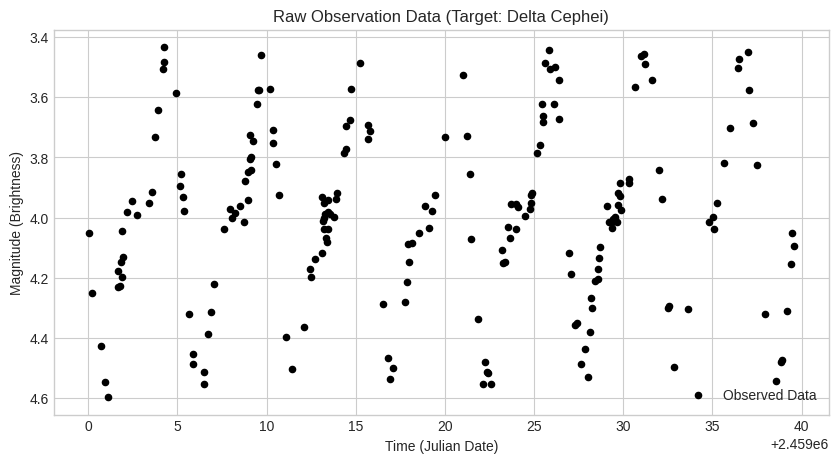

In [ ]:
# Plotting the Raw Light Curve
plt.figure(figsize=(10, 5))
plt.scatter(time_obs, mag_obs, color='black', s=20, label='Observed Data')

plt.xlabel('Time (Julian Date)')
plt.ylabel('Magnitude (Brightness)')
plt.title('Raw Observation Data (Target: Delta Cephei)')

# CRITICAL: Astronomy convention - Brighter stars have lower magnitude
plt.gca().invert_yaxis()

plt.legend()
plt.show()

## **Hands-on 1: Finding the Period (Phase Folding)**
The raw data looks messy because the observations are scattered. To see the pattern, we must **"Fold"** the data.
We stack the data on top of itself based on a guessed period.

**Instructions:**
1. Run the cell below.
2. Move the slider to change the Period.
3. Look for the value where the chaos turns into a clean wave.

In [ ]:
def plot_folded(period_guess):
    # Calculate Phase (0.0 to 1.0)
    phase = (time_obs % period_guess) / period_guess

    plt.figure(figsize=(8, 5))
    # Plot the folded data
    plt.scatter(phase, mag_obs, c='crimson', alpha=0.7, edgecolors='k')

    plt.title(f'Light Curve Folded at P = {period_guess:.3f} days')
    plt.xlabel('Phase')
    plt.ylabel('Magnitude')
    plt.ylim(3.2, 4.8)
    plt.gca().invert_yaxis() # Invert Y axis
    plt.grid(True)
    plt.show()

# Create the Interactive Slider
# We give a range of 2 days to 10 days
interact(plot_folded,
         period_guess=FloatSlider(value=5.0, min=2.0, max=10.0, step=0.01, description='Period (d):'));

interactive(children=(FloatSlider(value=5.0, description='Period (d):', max=10.0, min=2.0, step=0.01), Output(…

## **Hands-on 2: The Scientific Method (Lomb-Scargle)**
Guessing with a slider is good for intuition, but science needs precision.
We use the **Lomb-Scargle Periodogram** (standard in professional astronomy) to calculate the most likely period mathematically.

------------------------------------------------
COMPUTED PERIOD: 5.3371 days
------------------------------------------------


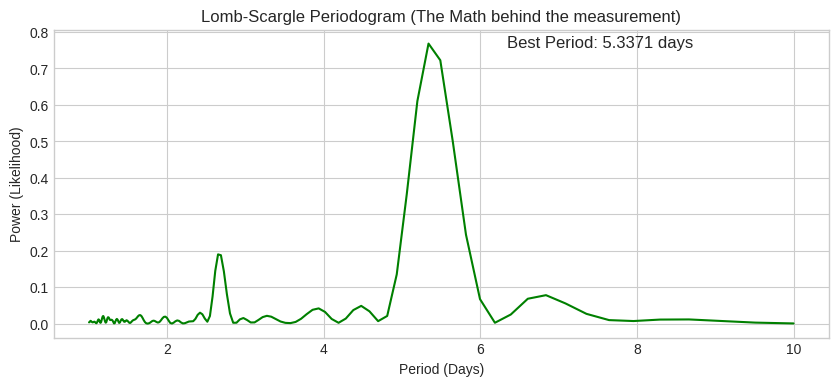

In [ ]:
# 1. Calculate Periodogram
frequency, power = LombScargle(time_obs, mag_obs).autopower(minimum_frequency=0.1, maximum_frequency=1.0)

# 2. Find the strongest signal (The highest peak in the graph)
best_freq = frequency[np.argmax(power)]
best_period = 1 / best_freq

print(f"------------------------------------------------")
print(f"COMPUTED PERIOD: {best_period:.4f} days")
print(f"------------------------------------------------")

# 3. Plot the Power Spectrum
plt.figure(figsize=(10, 4))
plt.plot(1/frequency, power, color='green')
plt.xlabel('Period (Days)')
plt.ylabel('Power (Likelihood)')

# mark the best period with an arrorw in the diagram
plt.annotate(f'Best Period: {best_period:.4f} days',
             xy=(1/best_freq + 1, np.max(power)-0.5),
             xytext=(1/best_freq + 1, np.max(power) - 0.01),
             fontsize=12)

plt.title('Lomb-Scargle Periodogram (The Math behind the measurement)')
plt.show()

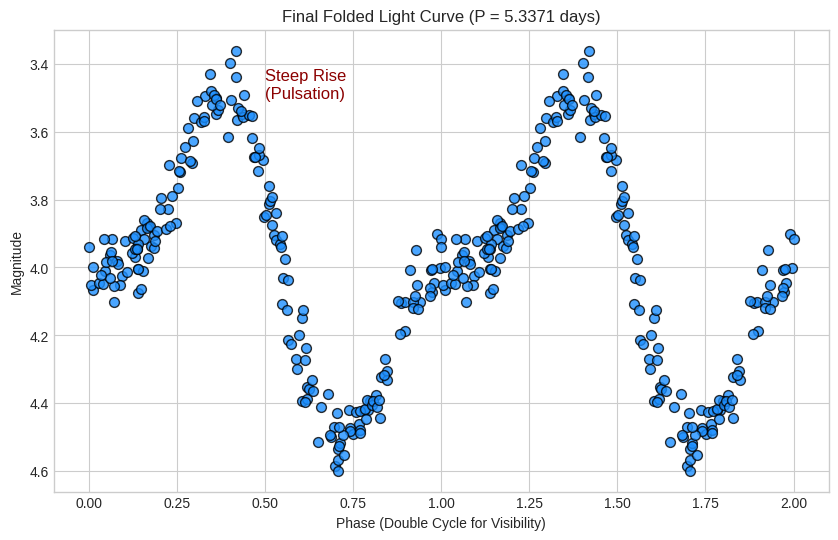

In [ ]:
# Calculate the phase using the mathematically best period
phase = (time_obs % best_period) / best_period

plt.figure(figsize=(10, 6))

# Plot Phase 0.0 to 1.0
plt.scatter(phase, mag_obs, c='dodgerblue', s=50, alpha=0.8, edgecolors='k', label='Primary Cycle')

# OPTIONAL TRICK: Plot Phase 1.0 to 2.0 (Repeating the data)
# This helps us see the continuity of the wave shape across the edge
plt.scatter(phase + 1, mag_obs, c='dodgerblue', s=50, alpha=0.8, edgecolors='k')

plt.xlabel('Phase (Double Cycle for Visibility)')
plt.ylabel('Magnitude')
plt.title(f'Final Folded Light Curve (P = {best_period:.4f} days)')
plt.gca().invert_yaxis() # Remember: Down is brighter!
plt.grid(True)

# Highlight the shape
plt.text(0.5, 3.5, "Steep Rise\n(Pulsation)", fontsize=12, color='darkred')
plt.show()

## **Scientific Inference: From Data to Physics**

We have determined the Period ($P \approx 5.36$ days) and the Shape (Asymmetric rise).

### **1. Star Classification**
* **Observation:** The light curve rises steeply and falls slowly (Sawtooth shape).
* **Inference:** This is a **Pulsating Variable** (Cepheid), not an Eclipsing Binary (which would have sharp, symmetric dips).



### **2. Measuring the Universe (Leavitt Law)**
Because it is a Cepheid, we can use Henrietta Leavitt's law to find its **Absolute Magnitude** ($M_v$) based purely on the period we just found.

$$M_v \approx -2.43 \log_{10}(P) - 4.05$$

Once we have the **Absolute Magnitude** ($M_v$) and our observed **Apparent Magnitude** ($m_v \approx 3.8$), we can calculate the distance ($d$) in parsecs:

$$d = 10^{\frac{m_v - M_v + 5}{5}}$$

**This is how amateur data contributes to measuring the scale of the galaxy.**

---
# **Part 2: Working with Real Data (OGLE-IV)**

Now we will replicate the actual scientific process using real data from the **OGLE-IV Survey**.
We will download the light curve of a Classical Cepheid in the **Large Magellanic Cloud (LMC)**, derive its period, and calculate its distance from Earth.

In [ ]:
# 1. Download Real Data from OGLE-IV (Warsaw University Observatory)
# Target: OGLE-LMC-CEP-0110 (A textbook Fundamental Mode Cepheid)
star_id = "OGLE-LMC-CEP-0110"
url = f"ftp://ftp.astrouw.edu.pl/ogle/ogle4/OCVS/lmc/cep/phot/I/{star_id}.dat"

print(f"Downloading data for {star_id}...")
!wget -q -O cepheid_data.dat {url}

# 2. Load the data using Pandas
# OGLE format: Column 0=Time(HJD), Column 1=Magnitude, Column 2=Error
df = pd.read_csv('cepheid_data.dat', delim_whitespace=True, names=['Time', 'Mag', 'Error'])

print(f"Loaded {len(df)} real observation points.")
print(df.head(3)) # Show first 3 rows

Loaded 753 real observation points.
         Time     Mag  Error
0  5261.55558  14.853  0.005
1  5261.57982  14.866  0.005
2  5262.57301  14.728  0.005


/tmp/ipython-input-4239693415.py:11: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv('cepheid_data.dat', delim_whitespace=True, names=['Time', 'Mag', 'Error'])


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 83.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 51.6 MB/s eta 0:00:00
1. Downloading OGLE-IV Identification Catalog...
   Found OGLE-LMC-CEP-0110 at RA: 04:48:58.97, Dec: -70:04:20.0
2. Downloading image from DSS2 Red survey...


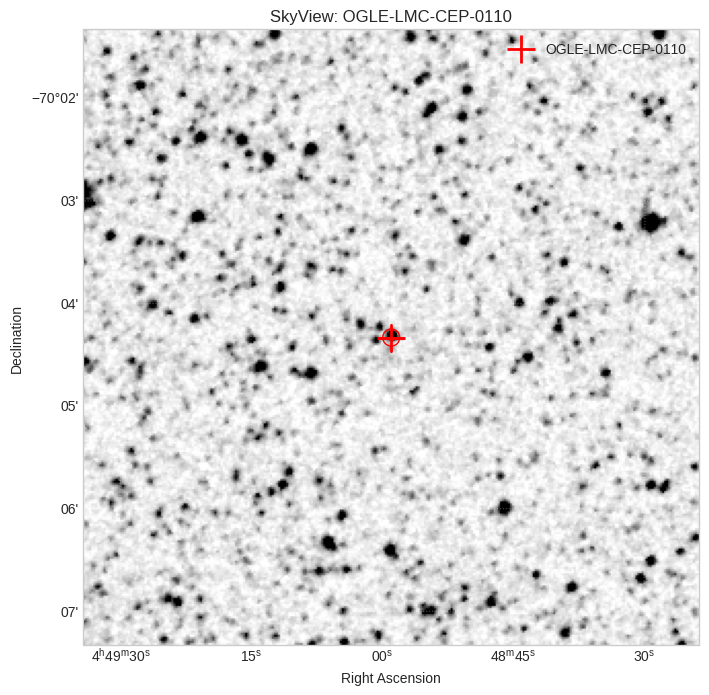

In [ ]:
# --- VISUALIZING THE TARGET (Source: OGLE-IV Catalog) ---

# 1. Install necessary libraries
!pip install -q astroquery

from astroquery.skyview import SkyView
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.wcs import WCS
import matplotlib.pyplot as plt
import pandas as pd
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')

# 2. Get Coordinates from the OGLE-IV Catalog
# The 'ident.dat' file contains: ID, RA, Dec for all stars in this collection
catalog_url = "ftp://ftp.astrouw.edu.pl/ogle/ogle4/OCVS/lmc/cep/ident.dat"
print("1. Downloading OGLE-IV Identification Catalog...")
!wget -q -O ident.dat {catalog_url}

# Load into Pandas (Columns: ID, RA, Dec, ...)
# OGLE 'ident.dat' format is whitespace separated
df_catalog = pd.read_csv('ident.dat', delim_whitespace=True, header=None, usecols=[0, 2, 3], names=['ID', 'RA', 'Dec'])

# Find our specific star
target_id = star_id
star_data = df_catalog[df_catalog['ID'] == target_id]

if not star_data.empty:
    ra_str = star_data.iloc[0]['RA']   # Format is usually 'HH:MM:SS.ss'
    dec_str = star_data.iloc[0]['Dec'] # Format is usually 'DD:MM:SS.ss'
    print(f"   Found {target_id} at RA: {ra_str}, Dec: {dec_str}")

    # Convert string coords to SkyCoord object
    target_coords = SkyCoord(f"{ra_str} {dec_str}", unit=(u.hourangle, u.deg), frame='icrs')

    # 3. Fetch the Image Cutout from SkyView (DSS2 Red)
    print(f"2. Downloading image from DSS2 Red survey...")
    hdu_list = SkyView.get_images(position=target_coords, survey=['DSS2 Red'], radius=3*u.arcmin)

    if len(hdu_list) > 0:
        image_data = hdu_list[0][0].data
        wcs_header = WCS(hdu_list[0][0].header)

        # 4. Plot the Image
        plt.figure(figsize=(8, 8))
        ax = plt.subplot(projection=wcs_header)

        # Inverted Grayscale (Standard for finder charts)
        plt.imshow(image_data, cmap='gray_r', origin='lower',
                   vmin=np.percentile(image_data, 5), vmax=np.percentile(image_data, 99))
        plt.xlabel('Right Ascension')
        plt.ylabel('Declination')

        # Add CROSSHAIR (Not a circle, to avoid confusion)
        ax.scatter(target_coords.ra.degree, target_coords.dec.degree,
                   transform=ax.get_transform('icrs'),
                   s=400, c='red', marker='+', linewidth=2, label=target_id)

        # Add open circle for clarity
        ax.scatter(target_coords.ra.degree, target_coords.dec.degree,
                   transform=ax.get_transform('icrs'),
                   s=150, facecolors='none', edgecolors='red', linewidth=1)

        plt.title(f'SkyView: {target_id}')
        plt.legend()
        plt.grid(color='white', ls=':', alpha=0.3)
        plt.show()
    else:
        print("Error: SkyView returned no images.")
else:
    print(f"Error: Could not find {target_id} in the OGLE catalog.")

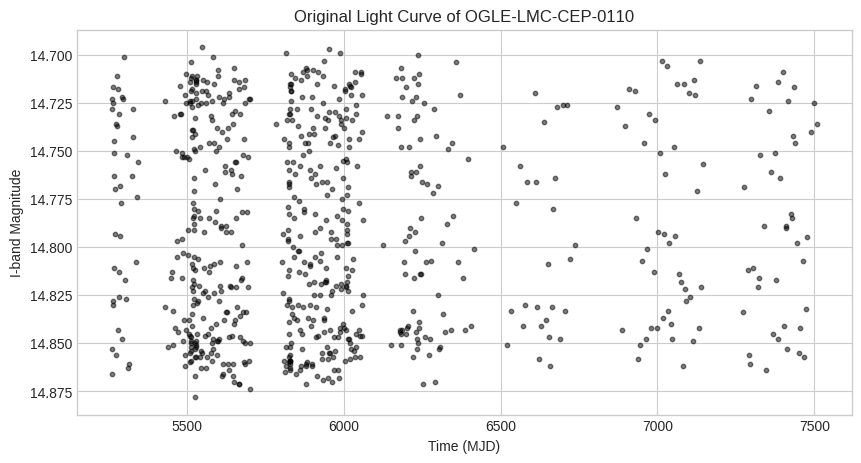

DERIVED PERIOD: 2.1200 days


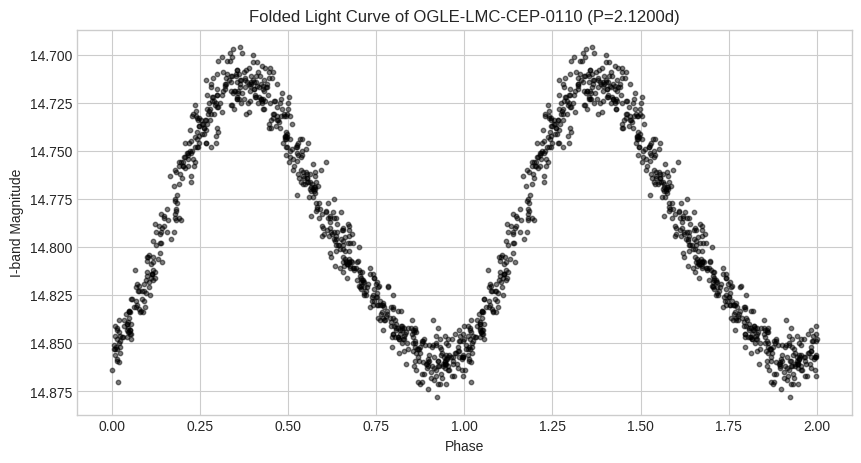

In [ ]:
# 1. Period Search on Real Data
time_real = df['Time'].values
mag_real = df['Mag'].values

plt.figure(figsize=(10, 5))
plt.scatter(time_real, mag_real, c='k', s=10, alpha=0.5, label='Real OGLE Data')
plt.gca().invert_yaxis()
plt.xlabel('Time (MJD)')
plt.ylabel('I-band Magnitude')
plt.title(f'Original Light Curve of {star_id}')
plt.grid(True)
plt.show()

# Calculate Periodogram
freq_real, power_real = LombScargle(time_real, mag_real).autopower(minimum_frequency=0.1, maximum_frequency=5)

# Find Best Period
best_freq_real = freq_real[np.argmax(power_real)]
real_period = 1 / best_freq_real

print(f"DERIVED PERIOD: {real_period:.4f} days")

# 2. Plot the Folded Light Curve
phase_real = (time_real % real_period) / real_period

plt.figure(figsize=(10, 5))
plt.scatter(phase_real, mag_real, c='k', s=10, alpha=0.5, label='Real OGLE Data')
plt.scatter(phase_real + 1, mag_real, c='k', s=10, alpha=0.5) # Repeat for visual continuity
plt.gca().invert_yaxis()
plt.xlabel('Phase')
plt.ylabel('I-band Magnitude')
plt.title(f'Folded Light Curve of {star_id} (P={real_period:.4f}d)')
plt.grid(True)
plt.show()

In [ ]:
# --- THE DISTANCE CALCULATION ---

# 1. Calculate Mean Apparent Magnitude (m)
# For accurate science, we usually integrate intensity, but mean magnitude is a good approximation here
# m_apparent = np.mean(mag_real)
m_apparent = np.median(mag_real)

# 2. Calculate Absolute Magnitude (M) using Leavitt Law
# Formula for LMC Fundamental Cepheids (Wesenheit/I-band approx from Soszynski et al. 2015)
# M = -3.32 * log10(Period) - 2.60
M_absolute = -3.32 * np.log10(real_period) - 2.60

# 3. Calculate Distance
# Distance Modulus Formula: m - M = 5 * log10(d) - 5
# Rearranged: d = 10 ^ ((m - M + 5) / 5)
distance_parsecs = 10 ** ((m_apparent - M_absolute + 5) / 5)
distance_kpc = distance_parsecs / 1000

print(f"Results for {star_id}:")
print(f"  Period:             {real_period:.4f} days")
print(f"  Apparent Mag (m):   {m_apparent:.2f}")
print(f"  Absolute Mag (M):   {M_absolute:.2f}")
print(f"------------------------------------------------")
print(f"  CALCULATED DISTANCE: {distance_kpc:.1f} kiloparsecs")
print(f"  ACCEPTED LMC DISTANCE: ~50.0 kiloparsecs")
print(f"------------------------------------------------")

Results for OGLE-LMC-CEP-0110:
  Period:             2.1200 days
  Apparent Mag (m):   14.80
  Absolute Mag (M):   -3.68
------------------------------------------------
  CALCULATED DISTANCE: 49.6 kiloparsecs
  ACCEPTED LMC DISTANCE: ~50.0 kiloparsecs
------------------------------------------------


## Thanks !!

Email: nitesh.kumar@ddn.upes.ac.in

Phone: +91 8742930496
